In [3]:
import re
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn.preprocessing
import torch

In [2]:
logs1 = """
2026-05-09 16:03:18
/home/pkw63980/ONNX-Net/src/onnxnet/search.py:115: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
2026-05-09 16:03:18
  dataset = pd.read_csv(args.data_path)
2026-05-09 16:03:29
Train size: 192232
2026-05-09 16:03:29
Map: 100%|██████████| 192232/192232 [12:33<00:00, 255.19 examples/s] 
2026-05-09 16:16:14
  0%|          | 0/1 [00:00<?, ?it/s]/home/pkw63980/ONNX-Net/.venv/lib/python3.13/site-packages/torch/_inductor/compile_fx.py:312: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
2026-05-09 16:16:26
  warnings.warn(
2026-05-09 16:16:36
100%|██████████| 1/1 [00:22<00:00, 22.05s/it]
2026-05-09 16:16:36
{'train_runtime': 22.0474, 'train_samples_per_second': 0.045, 'train_steps_per_second': 0.045, 'train_loss': 0.0, 'epoch': 1.0}
2026-05-09 16:16:36
Initial training done
2026-05-09 16:16:36
Predicting for iteration 1
2026-05-09 16:16:40
100%|██████████| 24029/24029 [4:18:31<00:00,  1.55it/s]  
2026-05-09 20:35:11
Prediction done
2026-05-09 20:35:11
Starting training for iteration 1
2026-05-09 20:35:12
100%|██████████| 1/1 [00:08<00:00,  8.22s/it]
2026-05-09 20:35:20
{'train_runtime': 8.244, 'train_samples_per_second': 0.485, 'train_steps_per_second': 0.121, 'train_loss': 0.859375, 'epoch': 1.0}
2026-05-09 20:35:21
Training done
2026-05-09 20:35:21
Num Samples: 4 | Best Accuracy: 91.9785 | Median Accuracy: 79.3389 | Mean Accuracy: 72.4070
2026-05-09 20:35:21
{5064, 10024, 152724, 181687}
2026-05-09 20:35:21
Predicting for iteration 2
2026-05-09 20:35:21
100%|██████████| 24029/24029 [4:21:10<00:00,  1.53it/s]  
2026-05-10 00:56:32
Prediction done
2026-05-10 00:56:32
Starting training for iteration 2
2026-05-10 00:56:32
100%|██████████| 1/1 [00:05<00:00,  5.12s/it]
2026-05-10 00:56:38
{'train_runtime': 5.1481, 'train_samples_per_second': 1.554, 'train_steps_per_second': 0.194, 'train_loss': 0.60546875, 'epoch': 1.0}
2026-05-10 00:56:38
Training done
2026-05-10 00:56:38
Num Samples: 8 | Best Accuracy: 94.3173 | Median Accuracy: 80.4708 | Mean Accuracy: 73.6528
2026-05-10 00:56:38
{22672, 10024, 152724, 181687, 5064, 112648, 174605, 23823}
2026-05-10 00:56:38
Predicting for iteration 3
2026-05-10 00:56:39
100%|██████████| 24029/24029 [4:17:47<00:00,  1.55it/s]  
2026-05-10 05:14:26
Prediction done
2026-05-10 05:14:26
Starting training for iteration 3
2026-05-10 05:14:27
100%|██████████| 1/1 [00:07<00:00,  7.02s/it]
2026-05-10 05:14:34
{'train_runtime': 7.0532, 'train_samples_per_second': 1.701, 'train_steps_per_second': 0.142, 'train_loss': 0.49609375, 'epoch': 1.0}
2026-05-10 05:14:34
Training done
2026-05-10 05:14:34
Num Samples: 12 | Best Accuracy: 94.3173 | Median Accuracy: 80.4708 | Mean Accuracy: 76.1164
2026-05-10 05:14:34
{28288, 10024, 5064, 112648, 107019, 174605, 23823, 22672, 117043, 152724, 181687, 703}
2026-05-10 05:14:34
Predicting for iteration 4
2026-05-10 05:14:35
100%|██████████| 24029/24029 [4:17:14<00:00,  1.56it/s]  
2026-05-10 09:31:50
Prediction done
2026-05-10 09:31:50
Starting training for iteration 4
2026-05-10 09:31:50
100%|██████████| 1/1 [00:08<00:00,  8.07s/it]
2026-05-10 09:31:58
{'train_runtime': 8.0848, 'train_samples_per_second': 1.979, 'train_steps_per_second': 0.124, 'train_loss': 0.41015625, 'epoch': 1.0}
2026-05-10 09:31:59
Training done
2026-05-10 09:31:59
Num Samples: 16 | Best Accuracy: 94.3173 | Median Accuracy: 80.4708 | Mean Accuracy: 77.2121
2026-05-10 09:31:59
{28288, 1729, 4068, 10024, 5064, 112648, 107019, 119497, 174605, 23823, 22672, 117043, 152724, 108019, 181687, 703}
2026-05-10 09:31:59
Predicting for iteration 5
2026-05-10 09:32:00
100%|██████████| 24029/24029 [4:17:18<00:00,  1.56it/s]  
2026-05-10 13:49:19
Prediction done
2026-05-10 13:49:19
Starting training for iteration 5
2026-05-10 13:49:19
100%|██████████| 2/2 [00:13<00:00,  6.64s/it]
2026-05-10 13:49:32
{'train_runtime': 13.2921, 'train_samples_per_second': 1.806, 'train_steps_per_second': 0.15, 'train_loss': 0.3720703125, 'epoch': 1.0}
2026-05-10 13:49:34
Training done
2026-05-10 13:49:34
Num Samples: 24 | Best Accuracy: 94.3173 | Median Accuracy: 72.6858 | Mean Accuracy: 74.9193
2026-05-10 13:49:34
{28288, 1729, 9221, 5064, 112648, 119497, 107019, 11658, 174605, 23823, 22672, 152724, 11681, 30691, 4068, 8998, 10024, 93487, 117043, 108019, 63925, 23862, 181687, 703}
2026-05-10 13:49:34
2026-05-11 09:55:28
Predicting for iteration 6
2026-05-11 09:55:31
100%|██████████| 24029/24029 [4:16:11<00:00,  1.56it/s]  
2026-05-11 14:11:42
Prediction done
2026-05-11 14:11:42
Starting training for iteration 6
2026-05-11 14:11:43
100%|██████████| 2/2 [00:17<00:00,  8.92s/it]
2026-05-11 14:12:00
{'train_runtime': 17.84, 'train_samples_per_second': 1.57, 'train_steps_per_second': 0.112, 'train_loss': 0.34375, 'epoch': 1.0}
2026-05-11 14:12:05
Training done
2026-05-11 14:12:05
Num Samples: 28 | Best Accuracy: 94.3173 | Median Accuracy: 72.6858 | Mean Accuracy: 73.6566
2026-05-11 14:12:05
{28288, 9221, 112648, 11658, 107019, 174605, 23823, 22672, 152724, 81182, 11681, 8998, 10024, 93487, 117043, 63925, 23862, 181687, 703, 1729, 11843, 5064, 119497, 78797, 15836, 30691, 4068, 108019}
2026-05-11 14:12:05
Predicting for iteration 7
2026-05-11 14:12:06
100%|██████████| 24029/24029 [4:16:39<00:00,  1.56it/s]  
2026-05-11 18:28:46
Prediction done
2026-05-11 18:28:46
Starting training for iteration 7
2026-05-11 18:28:46
100%|██████████| 2/2 [00:16<00:00,  8.01s/it]
2026-05-11 18:29:02
{'train_runtime': 16.0133, 'train_samples_per_second': 1.998, 'train_steps_per_second': 0.125, 'train_loss': 0.0594482421875, 'epoch': 1.0}
2026-05-11 18:29:03
Training done
2026-05-11 18:29:03
Num Samples: 32 | Best Accuracy: 94.4300 | Median Accuracy: 80.4708 | Mean Accuracy: 76.2295
2026-05-11 18:29:03
{28288, 9221, 112648, 11658, 107019, 174605, 94862, 23823, 22672, 152724, 81182, 81439, 11681, 8998, 10024, 93487, 117043, 63925, 23862, 181687, 703, 1729, 11843, 5064, 119497, 78797, 73178, 15836, 30691, 4068, 96622, 108019}
2026-05-11 18:29:03
Predicting for iteration 8
2026-05-11 18:29:04
100%|██████████| 24029/24029 [4:16:59<00:00,  1.56it/s]  
2026-05-11 22:46:03
Prediction done
2026-05-11 22:46:03
Starting training for iteration 8
2026-05-11 22:46:04
100%|██████████| 3/3 [00:24<00:00,  8.01s/it]
2026-05-11 22:46:28
{'train_runtime': 24.0452, 'train_samples_per_second': 1.996, 'train_steps_per_second': 0.125, 'train_loss': 0.145263671875, 'epoch': 1.0}
2026-05-11 22:46:28
Training done
2026-05-11 22:46:28
Num Samples: 48 | Best Accuracy: 94.4300 | Median Accuracy: 68.5852 | Mean Accuracy: 61.9186
2026-05-11 22:46:28
{28288, 9221, 112648, 11658, 107019, 174605, 94862, 23823, 22672, 152724, 81182, 81439, 160032, 11681, 188191, 187940, 8998, 155943, 10024, 93487, 117043, 63925, 23862, 181687, 155829, 166587, 187067, 189373, 703, 1729, 165569, 11843, 172867, 5064, 119497, 78797, 158680, 73178, 158938, 15836, 30691, 4068, 171237, 163561, 96622, 108019, 178933, 171642}
2026-05-11 22:46:28
Predicting for iteration 9
2026-05-11 22:46:29
100%|██████████| 24029/24029 [4:16:08<00:00,  1.56it/s]  
2026-05-12 03:02:38
Prediction done
2026-05-12 03:02:38
Starting training for iteration 9
2026-05-12 03:02:39
100%|██████████| 4/4 [00:31<00:00,  8.00s/it]
2026-05-12 03:03:11
{'train_runtime': 32.0207, 'train_samples_per_second': 1.999, 'train_steps_per_second': 0.125, 'train_loss': 0.11138916015625, 'epoch': 1.0}
2026-05-12 03:03:11
Training done
2026-05-12 03:03:11
Num Samples: 64 | Best Accuracy: 94.6600 | Median Accuracy: 92.2393 | Mean Accuracy: 69.8627
2026-05-12 03:03:11
{28288, 9221, 112648, 67464, 11658, 107019, 174605, 94862, 23823, 22672, 152724, 81182, 81439, 160032, 11681, 188191, 187940, 8998, 155943, 10024, 70572, 93487, 117043, 101683, 63925, 23862, 181687, 155829, 85301, 65466, 166587, 187067, 189373, 82357, 703, 112188, 1729, 165569, 11843, 172867, 110402, 5064, 119497, 78797, 65487, 105686, 158680, 73178, 158938, 15836, 66270, 79710, 77537, 30691, 4068, 171237, 163561, 101737, 63595, 96622, 108019, 178933, 171642, 64383}
2026-05-12 03:03:11
Predicting for iteration 10
2026-05-12 03:03:12
100%|██████████| 24029/24029 [4:17:13<00:00,  1.56it/s]  
2026-05-12 07:20:25
Prediction done
2026-05-12 07:20:26
Starting training for iteration 10
2026-05-12 07:20:26
100%|██████████| 6/6 [00:48<00:00,  8.00s/it]
2026-05-12 07:21:14
{'train_runtime': 48.0567, 'train_samples_per_second': 1.998, 'train_steps_per_second': 0.125, 'train_loss': 0.08412679036458333, 'epoch': 1.0}
2026-05-12 07:21:15
Training done
2026-05-12 07:21:15
Num Samples: 96 | Best Accuracy: 94.6600 | Median Accuracy: 93.4950 | Mean Accuracy: 77.9083
2026-05-12 07:21:15
{91392, 9221, 112648, 67338, 107019, 174605, 23823, 99090, 68376, 64795, 69917, 81182, 81439, 160032, 188191, 187940, 8998, 155943, 10024, 93487, 73007, 64049, 117043, 101683, 85301, 23862, 66616, 80443, 112188, 66621, 78398, 110402, 11843, 172867, 77128, 63560, 90455, 79710, 90724, 101737, 63595, 96622, 99694, 81520, 119408, 171642, 64383, 28288, 67464, 11658, 94862, 87695, 22672, 152724, 11681, 69537, 84907, 70572, 65202, 63925, 155829, 181687, 82357, 65466, 166587, 187067, 189373, 81342, 703, 1729, 165569, 71106, 71878, 5064, 119497, 78797, 65487, 105686, 158680, 66009, 73178, 158938, 15836, 69082, 66270, 77537, 30691, 4068, 171237, 83172, 163561, 68331, 108019, 91636, 178933, 69883}
2026-05-12 07:21:15
Predicting for iteration 11
2026-05-12 07:21:16
 44%|████▍     | 10587/24029 [2:21:59<3:25:09,  1.09it/s]
"""
logs2 = """
2026-05-09 16:03:18
/home/pkw63980/ONNX-Net/src/onnxnet/search.py:115: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
2026-05-09 16:03:18
  dataset = pd.read_csv(args.data_path)
2026-05-09 16:03:26
Train size: 192232
2026-05-09 16:03:26
Map: 100%|██████████| 192232/192232 [10:17<00:00, 311.18 examples/s] 
2026-05-09 16:13:58
  0%|          | 0/1 [00:00<?, ?it/s]/home/pkw63980/ONNX-Net/.venv/lib/python3.13/site-packages/torch/_inductor/compile_fx.py:312: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
2026-05-09 16:14:08
  warnings.warn(
2026-05-09 16:14:19
100%|██████████| 1/1 [00:20<00:00, 20.58s/it]
2026-05-09 16:14:19
{'train_runtime': 20.5885, 'train_samples_per_second': 0.049, 'train_steps_per_second': 0.049, 'train_loss': 0.0, 'epoch': 1.0}
2026-05-09 16:14:19
Initial training done
2026-05-09 16:14:19
Predicting for iteration 1
2026-05-09 16:14:22
100%|██████████| 24029/24029 [4:21:48<00:00,  1.53it/s]  
2026-05-09 20:36:11
Prediction done
2026-05-09 20:36:11
Starting training for iteration 1
2026-05-09 20:36:11
100%|██████████| 1/1 [00:06<00:00,  7.00s/it]
2026-05-09 20:36:18
{'train_runtime': 7.035, 'train_samples_per_second': 0.569, 'train_steps_per_second': 0.142, 'train_loss': 0.734375, 'epoch': 1.0}
2026-05-09 20:36:22
Training done
2026-05-09 20:36:22
Num Samples: 4 | Best Accuracy: 88.6000 | Median Accuracy: 72.3723 | Mean Accuracy: 67.9961
2026-05-09 20:36:22
{5064, 48217, 12012, 8998}
2026-05-09 20:36:22
Predicting for iteration 2
2026-05-09 20:36:23
100%|██████████| 24029/24029 [4:29:03<00:00,  1.49it/s]  
2026-05-10 01:05:26
Prediction done
2026-05-10 01:05:26
Starting training for iteration 2
2026-05-10 01:05:27
100%|██████████| 1/1 [00:05<00:00,  5.20s/it]
2026-05-10 01:05:32
{'train_runtime': 5.2327, 'train_samples_per_second': 1.529, 'train_steps_per_second': 0.191, 'train_loss': 0.58984375, 'epoch': 1.0}
2026-05-10 01:05:33
Training done
2026-05-10 01:05:33
Num Samples: 8 | Best Accuracy: 88.6000 | Median Accuracy: 69.3808 | Mean Accuracy: 63.0453
2026-05-10 01:05:33
{10024, 11843, 8998, 20263, 5064, 48217, 12012, 48172}
2026-05-10 01:05:33
Predicting for iteration 3
2026-05-10 01:05:34
100%|██████████| 24029/24029 [4:25:43<00:00,  1.51it/s]  
2026-05-10 05:31:18
Prediction done
2026-05-10 05:31:19
Starting training for iteration 3
2026-05-10 05:31:19
100%|██████████| 1/1 [00:06<00:00,  6.62s/it]
2026-05-10 05:31:26
{'train_runtime': 6.6371, 'train_samples_per_second': 1.808, 'train_steps_per_second': 0.151, 'train_loss': 0.40234375, 'epoch': 1.0}
2026-05-10 05:31:26
Training done
2026-05-10 05:31:26
Num Samples: 12 | Best Accuracy: 93.8700 | Median Accuracy: 72.3723 | Mean Accuracy: 67.0127
2026-05-10 05:31:26
{11843, 8998, 20263, 10024, 5064, 75335, 12012, 48172, 22672, 64344, 48217, 15836}
2026-05-10 05:31:26
Predicting for iteration 4
2026-05-10 05:31:27
100%|██████████| 24029/24029 [4:22:14<00:00,  1.53it/s]  
2026-05-10 09:53:42
Prediction done
2026-05-10 09:53:42
Starting training for iteration 4
2026-05-10 09:53:42
100%|██████████| 1/1 [00:08<00:00,  8.04s/it]
2026-05-10 09:53:50
{'train_runtime': 8.0616, 'train_samples_per_second': 1.985, 'train_steps_per_second': 0.124, 'train_loss': 0.373046875, 'epoch': 1.0}
2026-05-10 09:53:51
Training done
2026-05-10 09:53:51
Num Samples: 16 | Best Accuracy: 94.4400 | Median Accuracy: 72.3723 | Mean Accuracy: 66.6900
2026-05-10 09:53:51
{11843, 8998, 20263, 10024, 5064, 75335, 77241, 12012, 48172, 23823, 22672, 68371, 25430, 64344, 48217, 15836}
2026-05-10 09:53:51
Predicting for iteration 5
2026-05-10 09:53:52
100%|██████████| 24029/24029 [4:22:05<00:00,  1.53it/s]  
2026-05-10 14:15:58
Prediction done
2026-05-10 14:15:58
Starting training for iteration 5
2026-05-10 14:15:58
100%|██████████| 2/2 [00:13<00:00,  6.63s/it]
2026-05-10 14:16:11
{'train_runtime': 13.2816, 'train_samples_per_second': 1.807, 'train_steps_per_second': 0.151, 'train_loss': 0.3095703125, 'epoch': 1.0}
2026-05-10 14:16:12
Training done
2026-05-10 14:16:12
Num Samples: 24 | Best Accuracy: 94.4400 | Median Accuracy: 72.8404 | Mean Accuracy: 71.1455
2026-05-10 14:16:12
{28288, 74242, 11843, 105414, 75335, 5064, 67277, 23823, 22672, 68371, 25430, 64344, 48217, 19162, 15836, 66145, 12196, 8998, 20263, 10024, 12012, 48172, 77241, 703}
2026-05-10 14:16:12
2026-05-11 09:57:59
Predicting for iteration 6
2026-05-11 09:58:03
100%|██████████| 24029/24029 [4:21:30<00:00,  1.53it/s]  
2026-05-11 14:19:33
Prediction done
2026-05-11 14:19:33
Starting training for iteration 6
2026-05-11 14:19:34
100%|██████████| 2/2 [00:17<00:00,  8.92s/it]
2026-05-11 14:19:52
{'train_runtime': 17.8444, 'train_samples_per_second': 1.569, 'train_steps_per_second': 0.112, 'train_loss': 0.31298828125, 'epoch': 1.0}
2026-05-11 14:20:04
Training done
2026-05-11 14:20:04
Num Samples: 28 | Best Accuracy: 94.4400 | Median Accuracy: 72.3723 | Mean Accuracy: 70.6529
2026-05-11 14:20:04
{28288, 74242, 23823, 22672, 68371, 12196, 8998, 20263, 10024, 3496, 48172, 77241, 703, 1729, 11843, 105414, 75335, 5064, 67277, 25430, 64344, 48217, 19162, 15836, 66145, 12012, 3577, 17276}
2026-05-11 14:20:04
Predicting for iteration 7
2026-05-11 14:20:05
100%|██████████| 24029/24029 [4:22:13<00:00,  1.53it/s]  
2026-05-11 18:42:19
Prediction done
2026-05-11 18:42:19
Starting training for iteration 7
2026-05-11 18:42:20
100%|██████████| 2/2 [00:16<00:00,  8.03s/it]
2026-05-11 18:42:36
{'train_runtime': 16.0711, 'train_samples_per_second': 1.991, 'train_steps_per_second': 0.124, 'train_loss': 0.0169677734375, 'epoch': 1.0}
2026-05-11 18:42:37
Training done
2026-05-11 18:42:37
Num Samples: 32 | Best Accuracy: 94.7200 | Median Accuracy: 73.5908 | Mean Accuracy: 73.6194
2026-05-11 18:42:37
{28288, 74242, 23823, 22672, 68371, 67996, 12196, 8998, 20263, 10024, 3496, 48172, 77241, 79932, 92093, 703, 1729, 11843, 105414, 75335, 5064, 67277, 25430, 64344, 48217, 19162, 15836, 90589, 66145, 12012, 3577, 17276}
2026-05-11 18:42:37
Predicting for iteration 8
2026-05-11 18:42:38
100%|██████████| 24029/24029 [4:22:44<00:00,  1.52it/s]  
2026-05-11 23:05:23
Prediction done
2026-05-11 23:05:23
Starting training for iteration 8
2026-05-11 23:05:23
100%|██████████| 3/3 [00:24<00:00,  8.03s/it]
2026-05-11 23:05:47
{'train_runtime': 24.1194, 'train_samples_per_second': 1.99, 'train_steps_per_second': 0.124, 'train_loss': 0.022664388020833332, 'epoch': 1.0}
2026-05-11 23:05:48
Training done
2026-05-11 23:05:48
Num Samples: 48 | Best Accuracy: 94.9200 | Median Accuracy: 93.1450 | Mean Accuracy: 80.5090
2026-05-11 23:05:48
{28288, 74242, 88327, 73994, 23823, 22672, 68371, 76436, 67996, 12196, 8998, 20263, 10024, 3496, 86313, 48172, 70963, 77241, 79932, 92093, 703, 1729, 11843, 73925, 105414, 75335, 5064, 71878, 67277, 111822, 93265, 25430, 66262, 64344, 48217, 19162, 82393, 15836, 90589, 90205, 66145, 88419, 12012, 99055, 86135, 3577, 17276, 99326}
2026-05-11 23:05:48
Predicting for iteration 9
2026-05-11 23:05:49
100%|██████████| 24029/24029 [4:22:59<00:00,  1.52it/s]  
2026-05-12 03:28:49
Prediction done
2026-05-12 03:28:49
Starting training for iteration 9
2026-05-12 03:28:49
100%|██████████| 4/4 [00:32<00:00,  8.06s/it]
2026-05-12 03:29:22
{'train_runtime': 32.2791, 'train_samples_per_second': 1.983, 'train_steps_per_second': 0.124, 'train_loss': 0.01690673828125, 'epoch': 1.0}
2026-05-12 03:29:22
Training done
2026-05-12 03:29:22
Num Samples: 64 | Best Accuracy: 94.9200 | Median Accuracy: 94.1850 | Mean Accuracy: 84.0005
2026-05-12 03:29:22
{28288, 74242, 88327, 73994, 23823, 22672, 80018, 68371, 76436, 70811, 67996, 12196, 8998, 20263, 10024, 3496, 86313, 82603, 48172, 71343, 69680, 70963, 77241, 79932, 92093, 703, 1729, 11843, 73925, 105414, 75335, 5064, 71878, 67277, 111822, 93265, 98771, 25430, 66262, 64344, 48217, 19162, 82393, 15836, 90589, 90205, 73178, 72160, 66145, 119642, 88419, 66404, 106979, 66148, 86371, 12012, 69740, 99055, 96470, 86135, 3577, 17276, 66045, 99326}
2026-05-12 03:29:22
Predicting for iteration 10
2026-05-12 03:29:23
100%|██████████| 24029/24029 [4:23:06<00:00,  1.52it/s]  
2026-05-12 07:52:30
Prediction done
2026-05-12 07:52:30
Starting training for iteration 10
2026-05-12 07:52:31
100%|██████████| 6/6 [00:48<00:00,  8.06s/it]
2026-05-12 07:53:19
{'train_runtime': 48.3877, 'train_samples_per_second': 1.984, 'train_steps_per_second': 0.124, 'train_loss': 0.021759033203125, 'epoch': 1.0}
2026-05-12 07:53:20
Training done
2026-05-12 07:53:20
Num Samples: 96 | Best Accuracy: 94.9200 | Median Accuracy: 94.4050 | Mean Accuracy: 87.5041
2026-05-12 07:53:20
{74242, 84741, 88327, 113159, 73994, 23823, 68371, 67831, 81957, 8998, 20263, 10024, 86313, 64039, 48172, 69680, 70963, 79932, 77375, 11843, 75335, 119879, 73808, 93265, 99408, 81491, 25430, 64344, 48217, 119642, 79707, 114012, 90205, 66145, 88419, 66404, 66148, 86371, 90472, 69740, 70252, 97138, 86135, 105335, 17276, 28288, 116608, 22672, 80018, 76436, 80021, 112282, 70811, 67996, 12196, 3496, 82603, 71343, 104112, 77241, 106428, 92093, 703, 1729, 73925, 105414, 71878, 5064, 105159, 67277, 111822, 86481, 98771, 66262, 96470, 82393, 19162, 73178, 15836, 90589, 84699, 116698, 72160, 106977, 111841, 106979, 119016, 108777, 12012, 99055, 78068, 84470, 63991, 3577, 66045, 99326}
2026-05-12 07:53:20
Predicting for iteration 11
2026-05-12 07:53:21
 35%|███▍      | 8396/24029 [1:50:35<4:02:01,  1.08it/s]
"""
logs3 = """
2026-05-09 16:03:15
/home/pkw63980/ONNX-Net/src/onnxnet/search.py:115: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
2026-05-09 16:03:15
  dataset = pd.read_csv(args.data_path)
2026-05-09 16:03:23
Train size: 192232
2026-05-09 16:03:23
Map: 100%|██████████| 192232/192232 [08:58<00:00, 356.81 examples/s] 
2026-05-09 16:12:32
  0%|          | 0/1 [00:00<?, ?it/s]/home/pkw63980/ONNX-Net/.venv/lib/python3.13/site-packages/torch/_inductor/compile_fx.py:312: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
2026-05-09 16:12:47
  warnings.warn(
2026-05-09 16:12:57
100%|██████████| 1/1 [00:25<00:00, 25.28s/it]
2026-05-09 16:12:57
{'train_runtime': 25.2815, 'train_samples_per_second': 0.04, 'train_steps_per_second': 0.04, 'train_loss': 0.0, 'epoch': 1.0}
2026-05-09 16:12:57
Initial training done
2026-05-09 16:12:57
Predicting for iteration 1
2026-05-09 16:13:01
100%|██████████| 24029/24029 [4:17:02<00:00,  1.56it/s]  
2026-05-09 20:30:03
Prediction done
2026-05-09 20:30:03
Starting training for iteration 1
2026-05-09 20:30:04
100%|██████████| 1/1 [00:07<00:00,  7.39s/it]
2026-05-09 20:30:11
{'train_runtime': 7.4205, 'train_samples_per_second': 0.539, 'train_steps_per_second': 0.135, 'train_loss': 0.1748046875, 'epoch': 1.0}
2026-05-09 20:30:12
Training done
2026-05-09 20:30:12
Num Samples: 4 | Best Accuracy: 92.8700 | Median Accuracy: 55.4288 | Mean Accuracy: 56.8438
2026-05-09 20:30:12
{5064, 117512, 9250, 8998}
2026-05-09 20:30:12
Predicting for iteration 2
2026-05-09 20:30:13
100%|██████████| 24029/24029 [4:18:04<00:00,  1.55it/s]  
2026-05-10 00:48:17
Prediction done
2026-05-10 00:48:17
Starting training for iteration 2
2026-05-10 00:48:18
100%|██████████| 1/1 [00:05<00:00,  5.19s/it]
2026-05-10 00:48:23
{'train_runtime': 5.2344, 'train_samples_per_second': 1.528, 'train_steps_per_second': 0.191, 'train_loss': 0.2314453125, 'epoch': 1.0}
2026-05-10 00:48:24
Training done
2026-05-10 00:48:24
Num Samples: 8 | Best Accuracy: 93.5200 | Median Accuracy: 54.2066 | Mean Accuracy: 58.5239
2026-05-10 00:48:24
{117512, 9250, 10024, 11843, 8998, 5064, 95132, 15500}
2026-05-10 00:48:24
Predicting for iteration 3
2026-05-10 00:48:25
100%|██████████| 24029/24029 [4:17:17<00:00,  1.56it/s]  
2026-05-10 05:05:43
Prediction done
2026-05-10 05:05:43
Starting training for iteration 3
2026-05-10 05:05:44
100%|██████████| 1/1 [00:06<00:00,  6.98s/it]
2026-05-10 05:05:51
{'train_runtime': 7.0147, 'train_samples_per_second': 1.711, 'train_steps_per_second': 0.143, 'train_loss': 0.25, 'epoch': 1.0}
2026-05-10 05:05:51
Training done
2026-05-10 05:05:51
Num Samples: 12 | Best Accuracy: 93.5200 | Median Accuracy: 70.8296 | Mean Accuracy: 63.8184
2026-05-10 05:05:51
{9250, 11843, 63524, 8998, 117512, 10024, 5064, 15500, 22672, 15836, 95132, 96317}
2026-05-10 05:05:51
Predicting for iteration 4
2026-05-10 05:05:52
100%|██████████| 24029/24029 [4:17:26<00:00,  1.56it/s]  
2026-05-10 09:23:19
Prediction done
2026-05-10 09:23:19
Starting training for iteration 4
2026-05-10 09:23:20
100%|██████████| 1/1 [00:08<00:00,  8.04s/it]
2026-05-10 09:23:28
{'train_runtime': 8.0603, 'train_samples_per_second': 1.985, 'train_steps_per_second': 0.124, 'train_loss': 0.265625, 'epoch': 1.0}
2026-05-10 09:23:28
Training done
2026-05-10 09:23:28
Num Samples: 16 | Best Accuracy: 93.5200 | Median Accuracy: 70.8296 | Mean Accuracy: 64.1818
2026-05-10 09:23:28
{9250, 11843, 63524, 8998, 117512, 10024, 5064, 15500, 23823, 22672, 94448, 67708, 25430, 15836, 95132, 96317}
2026-05-10 09:23:28
Predicting for iteration 5
2026-05-10 09:23:29
100%|██████████| 24029/24029 [4:17:44<00:00,  1.55it/s]  
2026-05-10 13:41:14
Prediction done
2026-05-10 13:41:14
Starting training for iteration 5
2026-05-10 13:41:14
100%|██████████| 2/2 [00:13<00:00,  6.57s/it]
2026-05-10 13:41:27
{'train_runtime': 13.1522, 'train_samples_per_second': 1.825, 'train_steps_per_second': 0.152, 'train_loss': 0.2373046875, 'epoch': 1.0}
2026-05-10 13:41:28
Training done
2026-05-10 13:41:28
Num Samples: 24 | Best Accuracy: 93.5800 | Median Accuracy: 70.8296 | Mean Accuracy: 66.7194
2026-05-10 13:41:28
{28288, 11843, 68743, 117512, 5064, 15500, 23823, 22672, 1364, 25430, 19162, 15836, 95132, 82784, 9250, 63524, 12196, 8998, 10024, 82539, 94448, 67708, 96317, 703}
2026-05-10 13:41:28
Predicting for iteration 6
2026-05-11 09:54:13
100%|██████████| 24029/24029 [4:15:50<00:00,  1.57it/s]  
2026-05-11 14:10:04
Prediction done
2026-05-11 14:10:04
Starting training for iteration 6
2026-05-11 14:10:05
100%|██████████| 2/2 [00:17<00:00,  8.97s/it]
2026-05-11 14:10:23
{'train_runtime': 17.9342, 'train_samples_per_second': 1.561, 'train_steps_per_second': 0.112, 'train_loss': 0.240234375, 'epoch': 1.0}
2026-05-11 14:10:24
Training done
2026-05-11 14:10:24
Num Samples: 28 | Best Accuracy: 93.5800 | Median Accuracy: 70.9662 | Mean Accuracy: 67.8058
2026-05-11 14:10:24
{28288, 9859, 68743, 117512, 15500, 23823, 22672, 95132, 9250, 63524, 12196, 8998, 10024, 3496, 96317, 703, 66239, 1729, 11843, 5064, 1364, 25430, 19162, 15836, 82784, 82539, 94448, 67708}
2026-05-11 14:10:24
Predicting for iteration 7
2026-05-11 14:10:25
100%|██████████| 24029/24029 [4:16:08<00:00,  1.56it/s]  
2026-05-11 18:26:34
Prediction done
2026-05-11 18:26:34
Starting training for iteration 7
2026-05-11 18:26:34
100%|██████████| 2/2 [00:16<00:00,  8.01s/it]
2026-05-11 18:26:50
{'train_runtime': 16.0414, 'train_samples_per_second': 1.995, 'train_steps_per_second': 0.125, 'train_loss': 0.02349853515625, 'epoch': 1.0}
2026-05-11 18:26:51
Training done
2026-05-11 18:26:51
Num Samples: 32 | Best Accuracy: 94.2400 | Median Accuracy: 73.3624 | Mean Accuracy: 71.0510
2026-05-11 18:26:51
{28288, 9859, 68743, 117512, 15500, 23823, 22672, 95132, 9250, 63524, 12196, 8998, 10024, 3496, 96317, 703, 66239, 1729, 70463, 11843, 5064, 93265, 1364, 25430, 19162, 15836, 82784, 97124, 82539, 82285, 94448, 67708}
2026-05-11 18:26:51
Predicting for iteration 8
2026-05-11 18:26:52
100%|██████████| 24029/24029 [4:19:37<00:00,  1.54it/s]  
2026-05-11 22:46:29
Prediction done
2026-05-11 22:46:29
Starting training for iteration 8
2026-05-11 22:46:30
100%|██████████| 3/3 [00:24<00:00,  8.06s/it]
2026-05-11 22:46:54
{'train_runtime': 24.2107, 'train_samples_per_second': 1.983, 'train_steps_per_second': 0.124, 'train_loss': 0.034423828125, 'epoch': 1.0}
2026-05-11 22:46:55
Training done
2026-05-11 22:46:55
Num Samples: 48 | Best Accuracy: 94.5600 | Median Accuracy: 93.1050 | Mean Accuracy: 78.7505
2026-05-11 22:46:55
{28288, 9859, 68743, 117512, 113159, 102027, 15500, 64268, 66444, 23823, 22672, 90258, 95132, 70047, 9250, 63524, 12196, 8998, 10024, 3496, 109994, 96317, 703, 66239, 1729, 70463, 11843, 108735, 5064, 74186, 93265, 1364, 73940, 25430, 19162, 15836, 80349, 82784, 97124, 115816, 73704, 82539, 63724, 82285, 94448, 65913, 67708, 66045}
2026-05-11 22:46:55
Predicting for iteration 9
2026-05-11 22:46:56
100%|██████████| 24029/24029 [4:23:07<00:00,  1.52it/s]  
2026-05-12 03:10:04
Prediction done
2026-05-12 03:10:04
Starting training for iteration 9
2026-05-12 03:10:04
100%|██████████| 4/4 [00:32<00:00,  8.02s/it]
2026-05-12 03:10:36
{'train_runtime': 32.1274, 'train_samples_per_second': 1.992, 'train_steps_per_second': 0.125, 'train_loss': 0.036041259765625, 'epoch': 1.0}
2026-05-12 03:10:37
Training done
2026-05-12 03:10:37
Num Samples: 64 | Best Accuracy: 94.5600 | Median Accuracy: 93.2800 | Mean Accuracy: 82.3655
2026-05-12 03:10:37
{28288, 9859, 66564, 84099, 68743, 117512, 113159, 74890, 102027, 15500, 64268, 66444, 23823, 22672, 118028, 90258, 120085, 95132, 70047, 9250, 63524, 12196, 8998, 10024, 3496, 109994, 63668, 96317, 703, 66239, 1729, 70463, 11843, 108735, 73792, 71107, 82118, 5064, 74186, 74060, 100175, 93265, 100562, 1364, 73940, 25430, 67670, 76248, 19162, 15836, 80349, 82784, 97124, 115816, 73704, 82539, 63724, 82285, 94448, 71666, 65913, 71802, 67708, 66045}
2026-05-12 03:10:37
Predicting for iteration 10
2026-05-12 03:10:38
100%|██████████| 24029/24029 [4:20:53<00:00,  1.54it/s]  
2026-05-12 07:31:31
Prediction done
2026-05-12 07:31:31
Starting training for iteration 10
2026-05-12 07:31:32
100%|██████████| 6/6 [00:48<00:00,  8.03s/it]
2026-05-12 07:32:20
{'train_runtime': 48.2357, 'train_samples_per_second': 1.99, 'train_steps_per_second': 0.124, 'train_loss': 0.038431803385416664, 'epoch': 1.0}
2026-05-12 07:32:20
Training done
2026-05-12 07:32:20
Num Samples: 96 | Best Accuracy: 94.6200 | Median Accuracy: 93.6200 | Mean Accuracy: 86.2685
2026-05-12 07:32:20
{66564, 87046, 113159, 117512, 66314, 64268, 118028, 94476, 23823, 120085, 9250, 63524, 8998, 10024, 86313, 70704, 90418, 96317, 70463, 73792, 90178, 11843, 74060, 100175, 93265, 87121, 1364, 25430, 67670, 92760, 105815, 80733, 82784, 97124, 115816, 82539, 84588, 82285, 78701, 65913, 71802, 64121, 67708, 75903, 28288, 9859, 84099, 68743, 74890, 102027, 15500, 66444, 22672, 106641, 90258, 95132, 70047, 64928, 86178, 12196, 3496, 109994, 107690, 89263, 71343, 63668, 88501, 703, 66239, 1729, 108735, 71107, 71105, 89794, 82118, 93631, 5064, 74186, 65487, 100562, 73940, 76248, 19162, 15836, 80349, 76764, 63461, 90087, 73704, 63724, 94448, 71666, 66290, 83955, 79606, 66045}
2026-05-12 07:32:20
Predicting for iteration 11
2026-05-12 07:32:21
 41%|████      | 9871/24029 [2:11:35<3:35:13,  1.10it/s]
"""
logs4 = """
2026-05-09 16:03:17
/home/pkw63980/ONNX-Net/src/onnxnet/search.py:115: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
2026-05-09 16:03:17
  dataset = pd.read_csv(args.data_path)
2026-05-09 16:03:23
Train size: 192232
2026-05-09 16:03:24
Map: 100%|██████████| 192232/192232 [08:53<00:00, 360.65 examples/s] 
2026-05-09 16:12:32
  0%|          | 0/1 [00:00<?, ?it/s]/home/pkw63980/ONNX-Net/.venv/lib/python3.13/site-packages/torch/_inductor/compile_fx.py:312: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
2026-05-09 16:12:47
  warnings.warn(
2026-05-09 16:12:57
100%|██████████| 1/1 [00:25<00:00, 25.27s/it]
2026-05-09 16:12:57
{'train_runtime': 25.2753, 'train_samples_per_second': 0.04, 'train_steps_per_second': 0.04, 'train_loss': 0.0, 'epoch': 1.0}
2026-05-09 16:12:57
Initial training done
2026-05-09 16:12:57
Predicting for iteration 1
2026-05-09 16:13:01
100%|██████████| 24029/24029 [4:18:44<00:00,  1.55it/s]  
2026-05-09 20:31:45
Prediction done
2026-05-09 20:31:45
Starting training for iteration 1
2026-05-09 20:31:46
100%|██████████| 1/1 [00:06<00:00,  6.85s/it]
2026-05-09 20:31:53
{'train_runtime': 6.8706, 'train_samples_per_second': 0.582, 'train_steps_per_second': 0.146, 'train_loss': 0.640625, 'epoch': 1.0}
2026-05-09 20:31:57
Training done
2026-05-09 20:31:57
Num Samples: 4 | Best Accuracy: 93.7700 | Median Accuracy: 79.8989 | Mean Accuracy: 73.0519
2026-05-09 20:31:57
{5064, 110827, 137096, 8998}
2026-05-09 20:31:57
Predicting for iteration 2
2026-05-09 20:31:58
100%|██████████| 24029/24029 [4:19:26<00:00,  1.54it/s]  
2026-05-10 00:51:25
Prediction done
2026-05-10 00:51:25
Starting training for iteration 2
2026-05-10 00:51:25
100%|██████████| 1/1 [00:05<00:00,  5.14s/it]
2026-05-10 00:51:30
{'train_runtime': 5.1545, 'train_samples_per_second': 1.552, 'train_steps_per_second': 0.194, 'train_loss': 0.47265625, 'epoch': 1.0}
2026-05-10 00:51:31
Training done
2026-05-10 00:51:31
Num Samples: 8 | Best Accuracy: 94.4900 | Median Accuracy: 79.8989 | Mean Accuracy: 69.8065
2026-05-10 00:51:31
{104929, 10024, 11843, 137096, 8998, 5064, 110827, 91789}
2026-05-10 00:51:31
Predicting for iteration 3
2026-05-10 00:51:32
100%|██████████| 24029/24029 [4:18:39<00:00,  1.55it/s]  
2026-05-10 05:10:12
Prediction done
2026-05-10 05:10:12
Starting training for iteration 3
2026-05-10 05:10:12
100%|██████████| 1/1 [00:06<00:00,  6.63s/it]
2026-05-10 05:10:19
{'train_runtime': 6.6625, 'train_samples_per_second': 1.801, 'train_steps_per_second': 0.15, 'train_loss': 0.41796875, 'epoch': 1.0}
2026-05-10 05:10:19
Training done
2026-05-10 05:10:19
Num Samples: 12 | Best Accuracy: 94.4900 | Median Accuracy: 81.0308 | Mean Accuracy: 71.5001
2026-05-10 05:10:19
{104929, 11843, 102276, 8998, 10024, 137096, 5064, 110827, 91789, 22672, 94321, 15836}
2026-05-10 05:10:19
Predicting for iteration 4
2026-05-10 05:10:20
100%|██████████| 24029/24029 [4:18:39<00:00,  1.55it/s]  
2026-05-10 09:29:00
Prediction done
2026-05-10 09:29:00
Starting training for iteration 4
2026-05-10 09:29:01
100%|██████████| 1/1 [00:08<00:00,  8.08s/it]
2026-05-10 09:29:09
{'train_runtime': 8.1013, 'train_samples_per_second': 1.975, 'train_steps_per_second': 0.123, 'train_loss': 0.384765625, 'epoch': 1.0}
2026-05-10 09:29:09
Training done
2026-05-10 09:29:09
Num Samples: 16 | Best Accuracy: 94.4900 | Median Accuracy: 81.0308 | Mean Accuracy: 69.9131
2026-05-10 09:29:09
{101760, 104929, 11843, 102276, 8998, 10024, 137096, 5064, 110827, 91789, 23823, 22672, 94321, 25430, 15836, 92542}
2026-05-10 09:29:09
Predicting for iteration 5
2026-05-10 09:29:10
100%|██████████| 24029/24029 [4:19:06<00:00,  1.55it/s]  
2026-05-10 13:48:17
Prediction done
2026-05-10 13:48:17
Starting training for iteration 5
2026-05-10 13:48:17
100%|██████████| 2/2 [00:13<00:00,  6.58s/it]
2026-05-10 13:48:31
{'train_runtime': 13.1938, 'train_samples_per_second': 1.819, 'train_steps_per_second': 0.152, 'train_loss': 0.3076171875, 'epoch': 1.0}
2026-05-10 13:48:31
Training done
2026-05-10 13:48:31
Num Samples: 24 | Best Accuracy: 94.4900 | Median Accuracy: 73.8178 | Mean Accuracy: 72.1703
2026-05-10 13:48:31
{101760, 28288, 11843, 102276, 137096, 5064, 76, 91789, 23823, 22672, 86033, 25430, 19162, 15836, 114333, 104929, 12196, 8998, 10024, 110827, 115056, 94321, 92542, 703}
2026-05-10 13:48:31
2026-05-11 09:55:53
Predicting for iteration 6
2026-05-11 09:55:55
100%|██████████| 24029/24029 [4:16:17<00:00,  1.56it/s]  
2026-05-11 14:12:13
Prediction done
2026-05-11 14:12:13
Starting training for iteration 6
2026-05-11 14:12:13
100%|██████████| 2/2 [00:17<00:00,  8.83s/it]
2026-05-11 14:12:31
{'train_runtime': 17.6588, 'train_samples_per_second': 1.586, 'train_steps_per_second': 0.113, 'train_loss': 0.3486328125, 'epoch': 1.0}
2026-05-11 14:12:44
Training done
2026-05-11 14:12:44
Num Samples: 28 | Best Accuracy: 94.4900 | Median Accuracy: 73.8178 | Mean Accuracy: 73.1445
2026-05-11 14:12:44
{101760, 28288, 102276, 137096, 91789, 23823, 22672, 86033, 93724, 114333, 12196, 8998, 10024, 3496, 74796, 703, 1729, 11843, 5064, 76, 25430, 19162, 15836, 104929, 110827, 115056, 94321, 92542}
2026-05-11 14:12:44
Predicting for iteration 7
2026-05-11 14:12:45
100%|██████████| 24029/24029 [4:22:22<00:00,  1.53it/s]  
2026-05-11 18:35:07
Prediction done
2026-05-11 18:35:07
Starting training for iteration 7
2026-05-11 18:35:07
100%|██████████| 2/2 [00:16<00:00,  8.02s/it]
2026-05-11 18:35:23
{'train_runtime': 16.0484, 'train_samples_per_second': 1.994, 'train_steps_per_second': 0.125, 'train_loss': 0.0189208984375, 'epoch': 1.0}
2026-05-11 18:35:24
Training done
2026-05-11 18:35:24
Num Samples: 32 | Best Accuracy: 94.4900 | Median Accuracy: 89.9600 | Mean Accuracy: 75.7286
2026-05-11 18:35:24
{101760, 28288, 102276, 137096, 64268, 91789, 23823, 22672, 86033, 93724, 114333, 12196, 8998, 10024, 3496, 74796, 703, 1729, 11843, 5064, 102985, 76, 71372, 25430, 19162, 15836, 104929, 110827, 115056, 94321, 65913, 92542}
2026-05-11 18:35:24
Predicting for iteration 8
2026-05-11 18:35:25
100%|██████████| 24029/24029 [4:21:32<00:00,  1.53it/s]  
2026-05-11 22:56:58
Prediction done
2026-05-11 22:56:58
Starting training for iteration 8
2026-05-11 22:56:58
100%|██████████| 3/3 [00:24<00:00,  8.03s/it]
2026-05-11 22:57:22
{'train_runtime': 24.1129, 'train_samples_per_second': 1.991, 'train_steps_per_second': 0.124, 'train_loss': 0.0399169921875, 'epoch': 1.0}
2026-05-11 22:57:23
Training done
2026-05-11 22:57:23
Num Samples: 48 | Best Accuracy: 94.4900 | Median Accuracy: 92.7250 | Mean Accuracy: 81.5476
2026-05-11 22:57:23
{101760, 28288, 102276, 118788, 137096, 75019, 64268, 91789, 23823, 22672, 86033, 85656, 74265, 93724, 114333, 94364, 63904, 83747, 12196, 65573, 8998, 10024, 3496, 74796, 103084, 92973, 63789, 67249, 703, 1729, 11843, 5064, 102985, 81483, 76, 71372, 25430, 19162, 15836, 104929, 87274, 110827, 69487, 115056, 94321, 90360, 65913, 92542}
2026-05-11 22:57:23
Predicting for iteration 9
2026-05-11 22:57:24
100%|██████████| 24029/24029 [4:20:49<00:00,  1.54it/s]  
2026-05-12 03:18:13
Prediction done
2026-05-12 03:18:13
Starting training for iteration 9
2026-05-12 03:18:14
100%|██████████| 4/4 [00:31<00:00,  8.00s/it]
2026-05-12 03:18:46
{'train_runtime': 32.0136, 'train_samples_per_second': 1.999, 'train_steps_per_second': 0.125, 'train_loss': 0.049957275390625, 'epoch': 1.0}
2026-05-12 03:18:47
Training done
2026-05-12 03:18:47
Num Samples: 64 | Best Accuracy: 94.6600 | Median Accuracy: 93.2900 | Mean Accuracy: 84.6274
2026-05-12 03:18:47
{101760, 28288, 95874, 102276, 118788, 72838, 137096, 69640, 75019, 64268, 91789, 88845, 23823, 22672, 86033, 74894, 65040, 85656, 74265, 64922, 93724, 114333, 94364, 106269, 63904, 83747, 12196, 65573, 8998, 10024, 3496, 87805, 74796, 103084, 92973, 63789, 67249, 96310, 703, 1729, 99521, 11843, 5064, 102985, 81483, 76, 71372, 72532, 25430, 19162, 15836, 104929, 86372, 87274, 110827, 69487, 115056, 94321, 73455, 89331, 90360, 65913, 95357, 92542}
2026-05-12 03:18:47
Predicting for iteration 10
2026-05-12 03:18:48
100%|██████████| 24029/24029 [4:17:03<00:00,  1.56it/s]  
2026-05-12 07:35:51
Prediction done
2026-05-12 07:35:51
Starting training for iteration 10
2026-05-12 07:35:52
100%|██████████| 6/6 [00:47<00:00,  8.00s/it]
2026-05-12 07:36:40
{'train_runtime': 48.0013, 'train_samples_per_second': 2.0, 'train_steps_per_second': 0.125, 'train_loss': 0.038167317708333336, 'epoch': 1.0}
2026-05-12 07:36:40
Training done
2026-05-12 07:36:40
Num Samples: 96 | Best Accuracy: 94.7300 | Median Accuracy: 93.8150 | Mean Accuracy: 87.8430
2026-05-12 07:36:40
{86016, 118788, 69640, 75019, 64268, 88845, 23823, 65040, 86033, 74265, 93724, 106269, 115486, 83747, 78884, 65573, 8998, 73765, 10024, 80677, 81443, 98089, 74796, 92973, 63789, 104492, 63532, 96310, 11843, 102985, 81483, 76, 77903, 72532, 25430, 87383, 78943, 120416, 117600, 86372, 99948, 77165, 69487, 115056, 94321, 107376, 65913, 67706, 95357, 92542, 80253, 101760, 28288, 95874, 102276, 72838, 137096, 91789, 74894, 94862, 22672, 86927, 83602, 104341, 85656, 64922, 94364, 114333, 99742, 63904, 12196, 3496, 97704, 110251, 103084, 67503, 67249, 703, 1729, 99521, 5064, 118728, 70090, 71372, 104660, 19162, 15836, 104929, 87274, 110827, 73455, 89331, 90360, 71162, 119035, 87805}
2026-05-12 07:36:40
Predicting for iteration 11
2026-05-12 07:36:41
 40%|████      | 9633/24029 [2:07:35<3:38:35,  1.10it/s]
"""
logs5 = """
2026-05-09 16:03:15
/home/pkw63980/ONNX-Net/src/onnxnet/search.py:115: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
2026-05-09 16:03:15
  dataset = pd.read_csv(args.data_path)
2026-05-09 16:03:22
Train size: 192232
2026-05-09 16:03:23
Map: 100%|██████████| 192232/192232 [09:30<00:00, 337.23 examples/s] 
2026-05-09 16:13:05
  0%|          | 0/1 [00:00<?, ?it/s]/home/pkw63980/ONNX-Net/.venv/lib/python3.13/site-packages/torch/_inductor/compile_fx.py:312: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
2026-05-09 16:13:17
  warnings.warn(
2026-05-09 16:13:27
100%|██████████| 1/1 [00:22<00:00, 22.47s/it]
2026-05-09 16:13:28
{'train_runtime': 22.4757, 'train_samples_per_second': 0.044, 'train_steps_per_second': 0.044, 'train_loss': 0.0, 'epoch': 1.0}
2026-05-09 16:13:28
Initial training done
2026-05-09 16:13:28
Predicting for iteration 1
2026-05-09 16:13:30
100%|██████████| 24029/24029 [4:15:37<00:00,  1.57it/s]  
2026-05-09 20:29:08
Prediction done
2026-05-09 20:29:08
Starting training for iteration 1
2026-05-09 20:29:08
100%|██████████| 1/1 [00:07<00:00,  7.81s/it]
2026-05-09 20:29:16
{'train_runtime': 7.831, 'train_samples_per_second': 0.511, 'train_steps_per_second': 0.128, 'train_loss': 0.53515625, 'epoch': 1.0}
2026-05-09 20:29:21
Training done
2026-05-09 20:29:21
Num Samples: 4 | Best Accuracy: 80.5700 | Median Accuracy: 75.9989 | Mean Accuracy: 67.8019
2026-05-09 20:29:21
{5064, 36659, 34955, 8998}
2026-05-09 20:29:21
Predicting for iteration 2
2026-05-09 20:29:22
100%|██████████| 24029/24029 [4:17:06<00:00,  1.56it/s]  
2026-05-10 00:46:28
Prediction done
2026-05-10 00:46:28
Starting training for iteration 2
2026-05-10 00:46:29
100%|██████████| 1/1 [00:05<00:00,  5.14s/it]
2026-05-10 00:46:34
{'train_runtime': 5.168, 'train_samples_per_second': 1.548, 'train_steps_per_second': 0.193, 'train_loss': 0.50390625, 'epoch': 1.0}
2026-05-10 00:46:35
Training done
2026-05-10 00:46:35
Num Samples: 8 | Best Accuracy: 88.4448 | Median Accuracy: 75.9989 | Mean Accuracy: 65.4531
2026-05-10 00:46:35
{10024, 36659, 11843, 40827, 8998, 41734, 5064, 34955}
2026-05-10 00:46:35
Predicting for iteration 3
2026-05-10 00:46:36
100%|██████████| 24029/24029 [4:20:31<00:00,  1.54it/s]  
2026-05-10 05:07:07
Prediction done
2026-05-10 05:07:07
Starting training for iteration 3
2026-05-10 05:07:07
100%|██████████| 1/1 [00:06<00:00,  6.80s/it]
2026-05-10 05:07:14
{'train_runtime': 6.8204, 'train_samples_per_second': 1.759, 'train_steps_per_second': 0.147, 'train_loss': 0.42578125, 'epoch': 1.0}
2026-05-10 05:07:15
Training done
2026-05-10 05:07:15
Num Samples: 12 | Best Accuracy: 94.4200 | Median Accuracy: 77.1308 | Mean Accuracy: 68.6953
2026-05-10 05:07:15
{71778, 11843, 8998, 41734, 10024, 5064, 34955, 22672, 36659, 40827, 15836, 71262}
2026-05-10 05:07:15
Predicting for iteration 4
2026-05-10 05:07:16
100%|██████████| 24029/24029 [4:18:34<00:00,  1.55it/s]  
2026-05-10 09:25:50
Prediction done
2026-05-10 09:25:50
Starting training for iteration 4
2026-05-10 09:25:50
100%|██████████| 1/1 [00:08<00:00,  8.01s/it]
2026-05-10 09:25:58
{'train_runtime': 8.0418, 'train_samples_per_second': 1.99, 'train_steps_per_second': 0.124, 'train_loss': 0.3984375, 'epoch': 1.0}
2026-05-10 09:25:59
Training done
2026-05-10 09:25:59
Num Samples: 16 | Best Accuracy: 94.4200 | Median Accuracy: 73.3497 | Mean Accuracy: 65.4827
2026-05-10 09:25:59
{71778, 11843, 8998, 41734, 10024, 5064, 8392, 34955, 23823, 22672, 36659, 74388, 25430, 40827, 15836, 71262}
2026-05-10 09:25:59
Predicting for iteration 5
2026-05-10 09:26:00
100%|██████████| 24029/24029 [4:18:34<00:00,  1.55it/s]  
2026-05-10 13:44:35
Prediction done
2026-05-10 13:44:35
Starting training for iteration 5
2026-05-10 13:44:35
100%|██████████| 2/2 [00:13<00:00,  6.55s/it]
2026-05-10 13:44:48
{'train_runtime': 13.1285, 'train_samples_per_second': 1.828, 'train_steps_per_second': 0.152, 'train_loss': 0.322265625, 'epoch': 1.0}
2026-05-10 13:44:49
Training done
2026-05-10 13:44:49
Num Samples: 24 | Best Accuracy: 94.4200 | Median Accuracy: 73.8178 | Mean Accuracy: 70.4086
2026-05-10 13:44:49
{28288, 11843, 41734, 5064, 8392, 34955, 23823, 22672, 70738, 74388, 78101, 25430, 19162, 15836, 71262, 71778, 12196, 8998, 10024, 103794, 36659, 40827, 92157, 703}
2026-05-10 13:44:49
Predicting for iteration 6
2026-05-11 09:59:10
100%|██████████| 24029/24029 [4:20:21<00:00,  1.54it/s]  
2026-05-11 14:19:32
Prediction done
2026-05-11 14:19:32
Starting training for iteration 6
2026-05-11 14:19:33
100%|██████████| 2/2 [00:18<00:00,  9.43s/it]
2026-05-11 14:19:51
{'train_runtime': 18.8858, 'train_samples_per_second': 1.483, 'train_steps_per_second': 0.106, 'train_loss': 0.3291015625, 'epoch': 1.0}
2026-05-11 14:20:04
Training done
2026-05-11 14:20:04
Num Samples: 28 | Best Accuracy: 94.4200 | Median Accuracy: 72.6858 | Mean Accuracy: 70.7157
2026-05-11 14:20:04
{28288, 41734, 34955, 23823, 22672, 74388, 78101, 2845, 12196, 8998, 10024, 36659, 703, 1729, 11843, 8392, 5064, 70738, 25430, 19162, 15836, 71262, 71778, 4068, 84587, 103794, 40827, 92157}
2026-05-11 14:20:04
Predicting for iteration 7
2026-05-11 14:20:05
100%|██████████| 24029/24029 [4:18:37<00:00,  1.55it/s]  
2026-05-11 18:38:42
Prediction done
2026-05-11 18:38:42
Starting training for iteration 7
2026-05-11 18:38:43
100%|██████████| 2/2 [00:16<00:00,  8.06s/it]
2026-05-11 18:38:59
{'train_runtime': 16.1373, 'train_samples_per_second': 1.983, 'train_steps_per_second': 0.124, 'train_loss': 0.0181884765625, 'epoch': 1.0}
2026-05-11 18:38:59
Training done
2026-05-11 18:38:59
Num Samples: 32 | Best Accuracy: 94.5300 | Median Accuracy: 77.1308 | Mean Accuracy: 73.6515
2026-05-11 18:38:59
{28288, 41734, 34955, 64268, 99724, 23823, 22672, 74388, 78101, 2845, 12196, 8998, 10024, 36659, 703, 1729, 11843, 8392, 5064, 75214, 70738, 25430, 19162, 15836, 71262, 71778, 4068, 84587, 103794, 65913, 40827, 92157}
2026-05-11 18:38:59
Predicting for iteration 8
2026-05-11 18:39:00
100%|██████████| 24029/24029 [4:18:40<00:00,  1.55it/s]  
2026-05-11 22:57:41
Prediction done
2026-05-11 22:57:41
Starting training for iteration 8
2026-05-11 22:57:42
100%|██████████| 3/3 [00:24<00:00,  8.01s/it]
2026-05-11 22:58:06
{'train_runtime': 24.058, 'train_samples_per_second': 1.995, 'train_steps_per_second': 0.125, 'train_loss': 0.025105794270833332, 'epoch': 1.0}
2026-05-11 22:58:06
Training done
2026-05-11 22:58:06
Num Samples: 48 | Best Accuracy: 94.7500 | Median Accuracy: 93.4650 | Mean Accuracy: 80.5321
2026-05-11 22:58:06
{28288, 66045, 41734, 34955, 64268, 99724, 23823, 22672, 74388, 78101, 2845, 12196, 78884, 8998, 80677, 10024, 117934, 36659, 103990, 80253, 94525, 703, 86720, 1729, 11843, 8392, 5064, 70090, 75214, 77903, 70738, 72532, 25430, 19162, 15836, 71262, 110048, 70368, 71778, 4068, 66404, 71529, 84587, 70252, 103794, 65913, 40827, 92157}
2026-05-11 22:58:06
Predicting for iteration 9
2026-05-11 22:58:07
100%|██████████| 24029/24029 [4:19:06<00:00,  1.55it/s]  
2026-05-12 03:17:14
Prediction done
2026-05-12 03:17:14
Starting training for iteration 9
2026-05-12 03:17:14
100%|██████████| 4/4 [00:32<00:00,  8.02s/it]
2026-05-12 03:17:46
{'train_runtime': 32.0855, 'train_samples_per_second': 1.995, 'train_steps_per_second': 0.125, 'train_loss': 0.03656005859375, 'epoch': 1.0}
2026-05-12 03:17:47
Training done
2026-05-12 03:17:47
Num Samples: 64 | Best Accuracy: 94.7500 | Median Accuracy: 93.5700 | Mean Accuracy: 83.8537
2026-05-12 03:17:47
{28288, 66045, 41734, 80262, 70026, 34955, 64268, 99724, 23823, 22672, 74388, 78101, 73239, 84888, 69402, 2845, 111261, 66337, 12196, 78884, 8998, 80677, 10024, 79530, 64685, 117934, 92594, 36659, 78260, 103990, 106682, 80253, 94525, 703, 86720, 1729, 11843, 8392, 5064, 70090, 75214, 77903, 71377, 70738, 81363, 72532, 25430, 82136, 19162, 15836, 71262, 110048, 70368, 71778, 4068, 66404, 71529, 84587, 70252, 103794, 78197, 65913, 40827, 92157}
2026-05-12 03:17:47
Predicting for iteration 10
2026-05-12 03:17:48
100%|██████████| 24029/24029 [4:19:21<00:00,  1.54it/s]  
2026-05-12 07:37:10
Prediction done
2026-05-12 07:37:10
Starting training for iteration 10
2026-05-12 07:37:10
100%|██████████| 6/6 [00:48<00:00,  8.02s/it]
2026-05-12 07:37:58
{'train_runtime': 48.1187, 'train_samples_per_second': 1.995, 'train_steps_per_second': 0.125, 'train_loss': 0.027089436848958332, 'epoch': 1.0}
2026-05-12 07:37:59
Training done
2026-05-12 07:37:59
Num Samples: 96 | Best Accuracy: 94.8400 | Median Accuracy: 93.9750 | Mean Accuracy: 87.2524
2026-05-12 07:37:59
{64769, 41734, 64268, 94476, 23823, 78101, 73239, 69402, 2845, 98590, 66337, 78371, 78884, 80677, 8998, 10024, 63528, 93488, 92157, 36659, 103990, 79932, 94525, 11843, 102477, 77903, 87121, 70738, 72532, 25430, 77910, 71262, 71778, 66404, 71529, 101737, 84587, 70252, 94059, 69743, 103794, 69234, 78197, 65913, 103801, 40827, 80253, 28288, 94594, 80262, 70026, 34955, 99724, 22672, 72338, 74388, 84888, 100505, 99483, 67996, 111261, 12196, 79530, 70572, 64685, 117934, 92594, 107954, 78260, 106682, 99005, 703, 86720, 1729, 96704, 79554, 64199, 8392, 5064, 70090, 93895, 75214, 71377, 81363, 105686, 82136, 19162, 15836, 110048, 70368, 88290, 4068, 65001, 88814, 96495, 66045}
2026-05-12 07:37:59
Predicting for iteration 11
2026-05-12 07:38:00
 40%|███▉      | 9525/24029 [2:06:51<3:43:15,  1.08it/s]
"""

In [4]:
scaler = sklearn.preprocessing.QuantileTransformer()
scaler.fit(np.array(torch.load("saved_valacc.pkl"))[..., None])

nb201 = pd.read_csv("nb201_search_eff_allnas.csv")
nb201["representation"] = nb201["representation"].str.strip()
nb201t = pd.read_csv("nb201_search_eff_allnast.csv")
nb201t["representation"] = nb201t["representation"].str.strip()
nb101 = pd.read_csv("nb101_search_eff_allnas.csv")
nb101["representation"] = nb101["representation"].str.strip()
nb101["av_best_acc"] = scaler.inverse_transform(nb101["av_best_acc"].to_numpy()[..., None])[..., 0]
nb101["av_median_acc"] = scaler.inverse_transform(nb101["av_median_acc"].to_numpy()[..., None])[..., 0]
nb101["av_mean_acc"] = scaler.inverse_transform(nb101["av_mean_acc"].to_numpy()[..., None])[..., 0]
nb301 = pd.read_csv("nb301_search_eff_allnas.csv")
nb301["representation"] = nb301["representation"].str.strip()

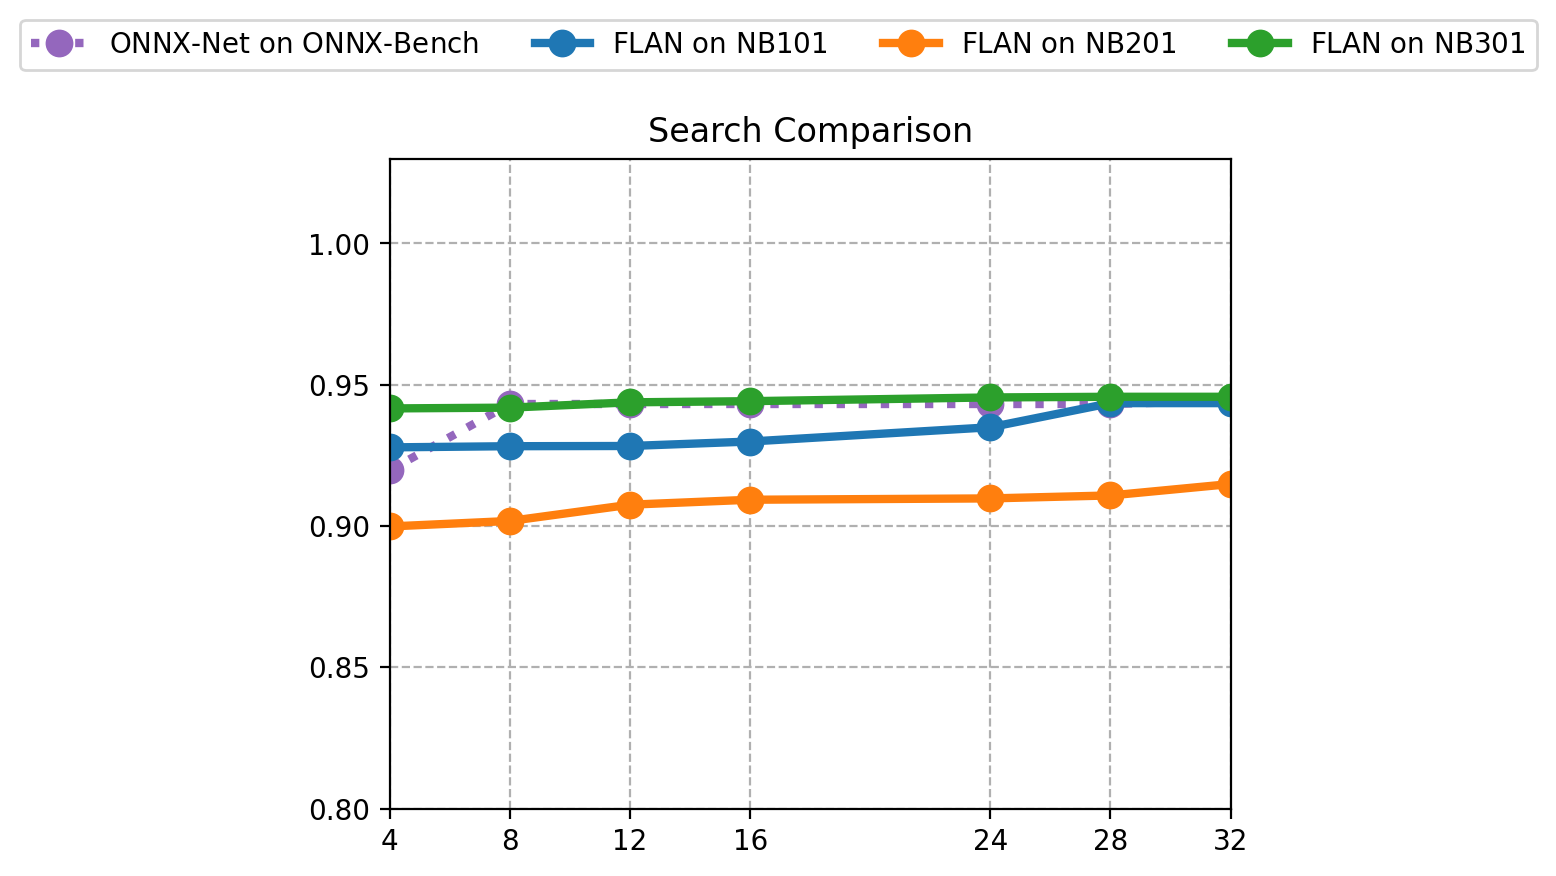

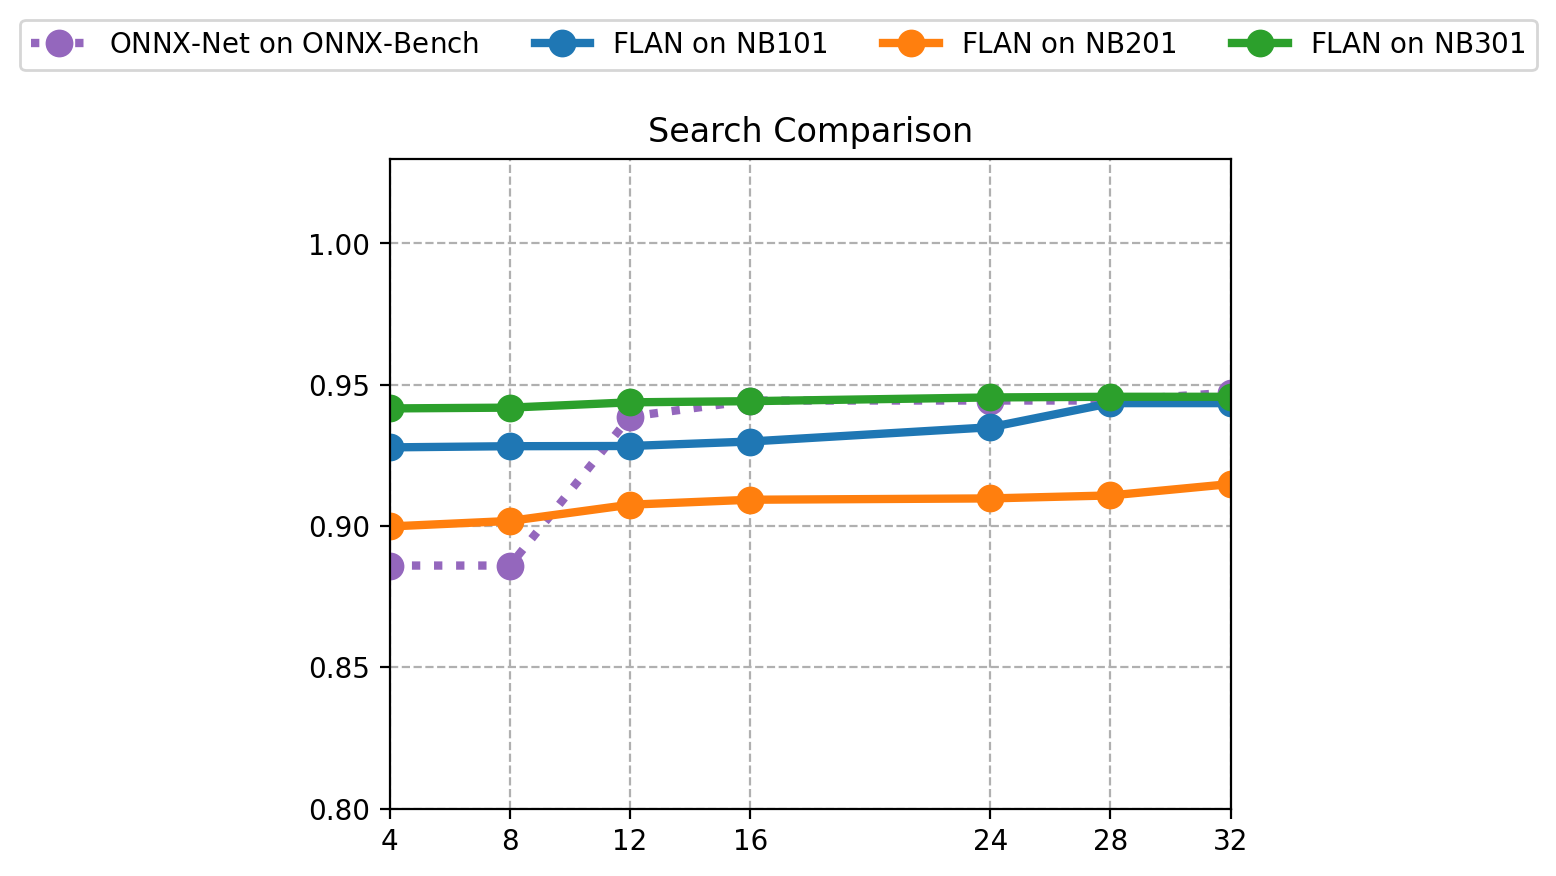

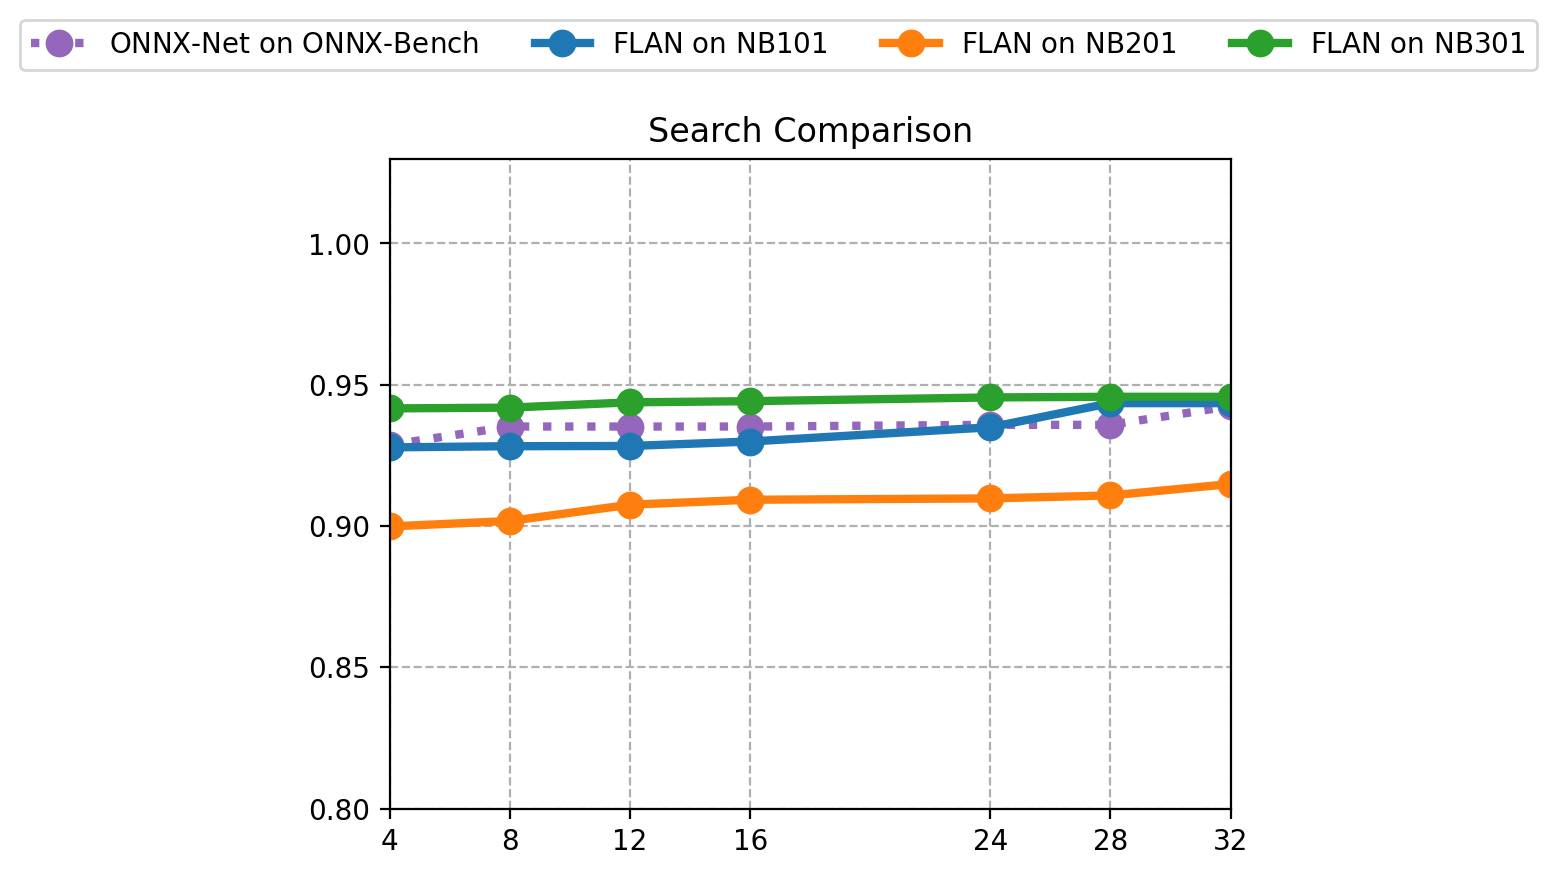

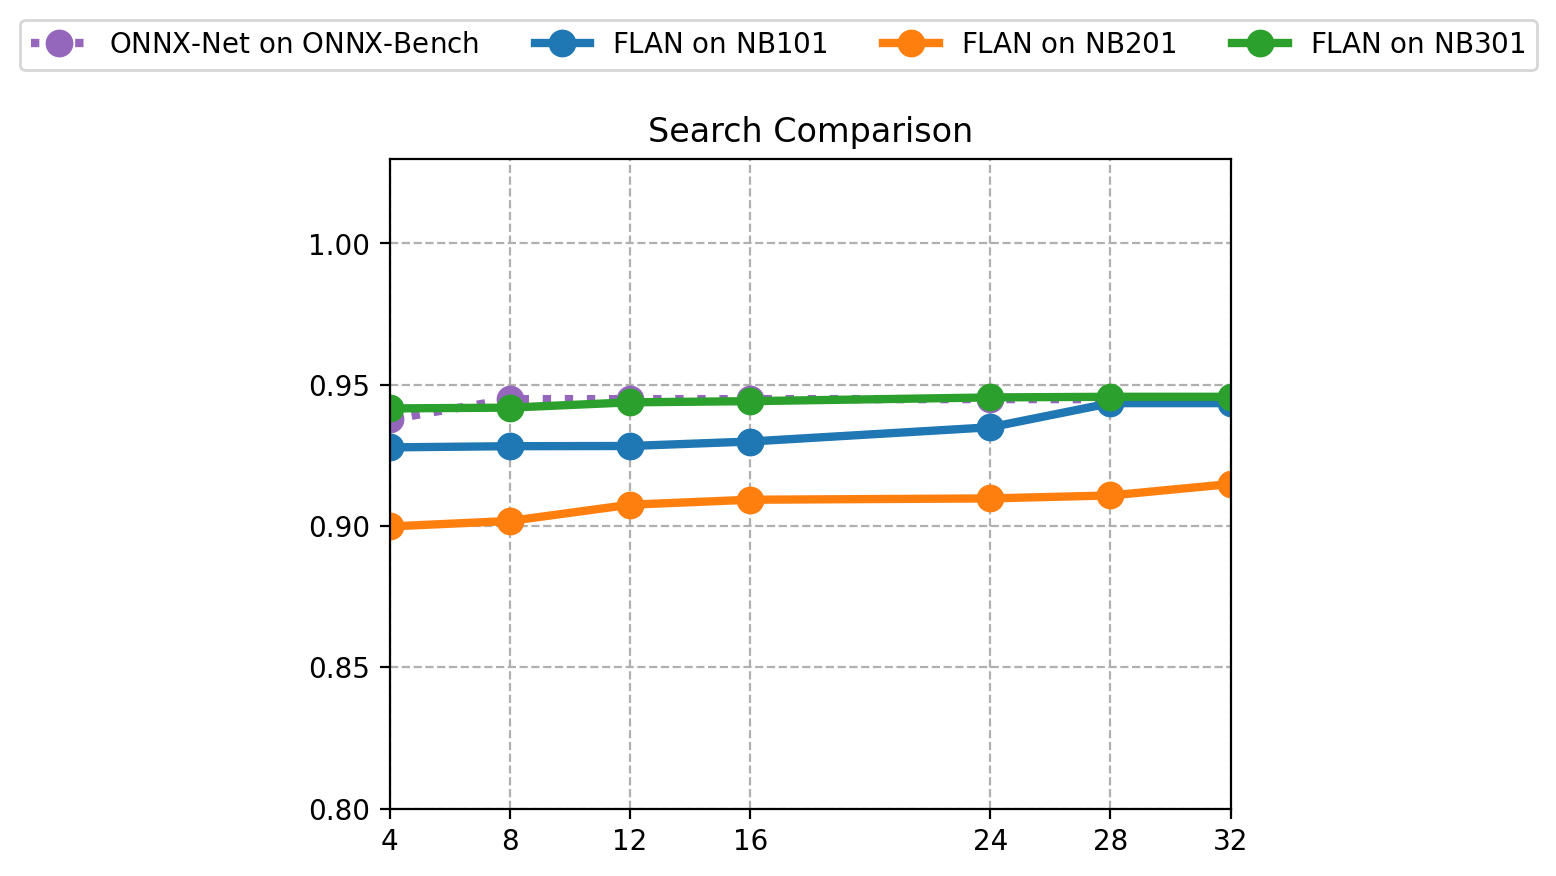

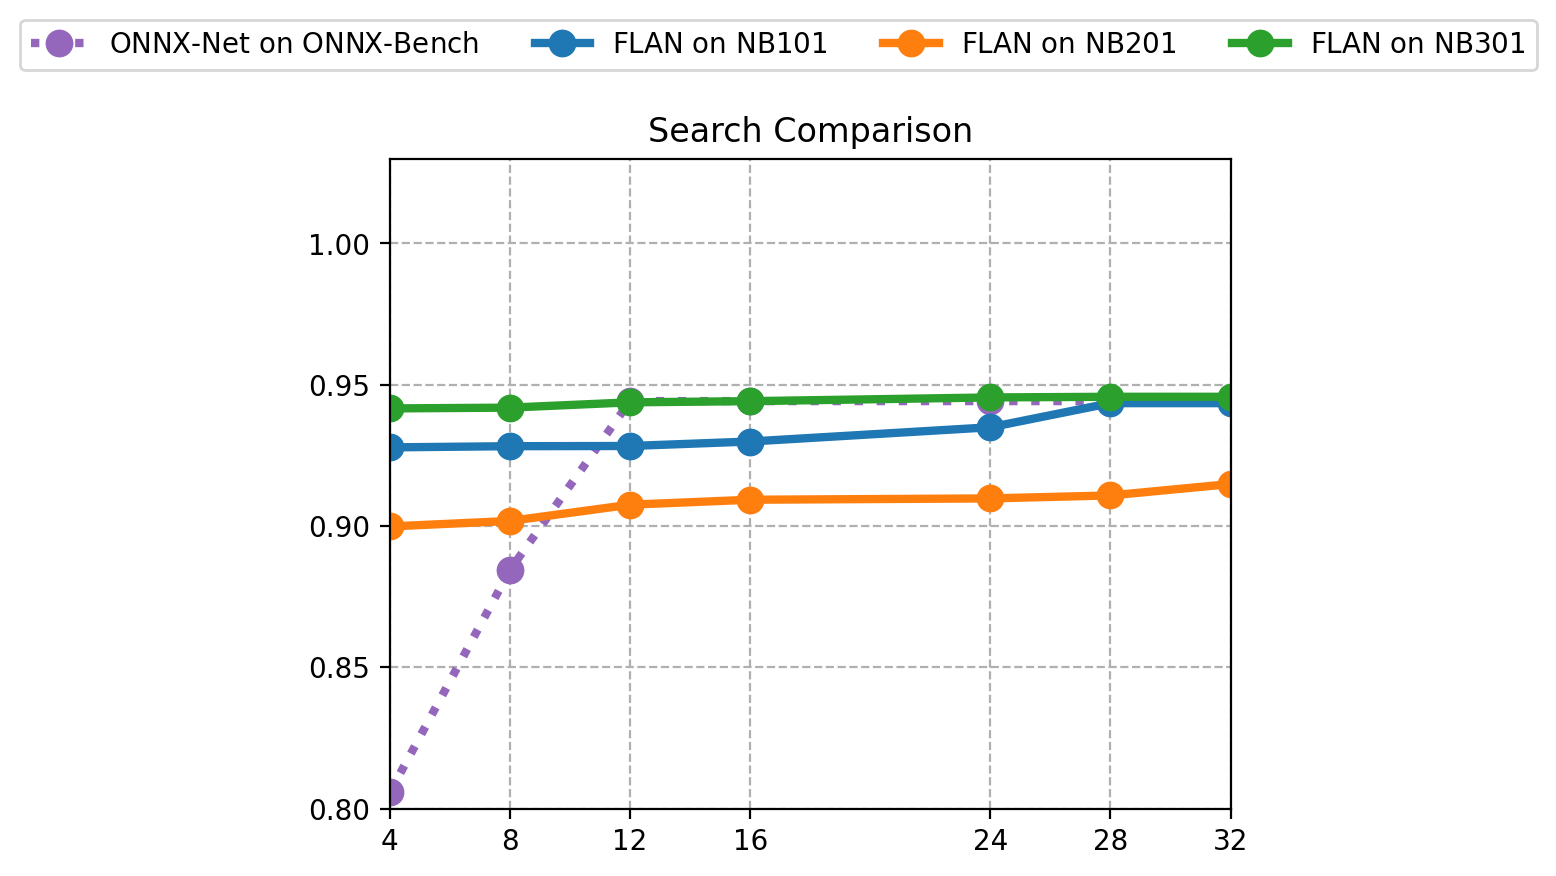

In [6]:
for i in [1,2,3,4,5]:
    logs = globals()[f"logs{i}"]

    best_accuracies = []
    median_accuracies = []
    mean_accuracies = []
    num_samples = []

    for line in logs.splitlines():
        if "Num Samples" in line:
            match = cast("re.Match[str]", re.search(r"Num Samples: (\d+) \| Best Accuracy: ([\d.]+) \| Median Accuracy: ([\d.]+) \| Mean Accuracy: ([\d.]+)", line))
            num_samples.append(int(match.group(1)))
            best_accuracies.append(float(match.group(2)))
            median_accuracies.append(float(match.group(3)))
            mean_accuracies.append(float(match.group(4)))

    """plt.figure()
    plt.suptitle("Search results on ONNX-Bench")
    plt.plot(num_samples, best_accuracies, label="Best Accuracy")
    plt.plot(num_samples, median_accuracies, label="Median Accuracy")
    plt.plot(num_samples, mean_accuracies, label="Mean Accuracy")
    # plt.xlim(0, 32)
    plt.legend()
    plt.show()
    pass"""

    plt.figure(figsize=(5,4), dpi=200)
    plt.plot(num_samples, np.array(best_accuracies) / 100.0, "o:", color="C4", linewidth=3, markersize=9, label=r"$\text{ONNX-Net on ONNX-Bench}$")
    plt.xticks([4, 8, 12, 16, 24, 28, 32], ["4", "8", "12", "16", "24", "28", "32"])
    plt.xlim(4, 32)
    plt.yticks(np.arange(0.8, 1.03, 0.05))
    plt.ylim(0.8, 1.03)
    plt.grid(linestyle="--")
    plt.title("Search Comparison")
    tmp = nb101[nb101["representation"] == "adj_gin"]
    plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C0", label=r"$\text{FLAN on NB101}$", linewidth=3, markersize=9)
    tmp = nb201[nb201["representation"] == "adj_gin"]
    plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C1", label=r"$\text{FLAN on NB201}$", linewidth=3, markersize=9)
    tmp = nb301[nb301["representation"] == "adj_gin"]
    plt.plot(tmp["num_samps"].tolist(), [x/100.0 for x in tmp["av_best_acc"].tolist()], "o-", color="C2", label=r"$\text{FLAN on NB301}$", linewidth=3, markersize=9)
    plt.gcf().legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.1))
    plt.tight_layout()
    pass

In [15]:
print("+--------+" + "-------+" * len(num_samples))
print("|        |" + "  |".join(f"   {x:<2d}" for x in num_samples) + "  |")
print("+--------+" + "-------+" * len(num_samples))
print("|  Best  |" + " |".join(f" {x:<.2f}" for x in best_accuracies) + " |")
print("+--------+" + "-------+" * len(num_samples))
print("| Median |" + " |".join(f" {x:<.2f}" for x in median_accuracies) + " |")
print("+--------+" + "-------+" * len(num_samples))
print("|  Mean  |" + " |".join(f" {x:<.2f}" for x in mean_accuracies) + " |")
print("+--------+" + "-------+" * len(num_samples))

+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
|        |   4   |   8   |   12  |   16  |   24  |   28  |   32  |   48  |   64  |   96  |
+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
|  Best  | 94.37 | 94.37 | 94.37 | 94.37 | 94.37 | 94.37 | 94.37 | 94.79 | 94.79 | 94.79 |
+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
| Median | 70.15 | 70.15 | 57.06 | 65.65 | 65.65 | 66.24 | 66.41 | 75.21 | 93.23 | 93.59 |
+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
|  Mean  | 58.70 | 50.43 | 46.36 | 50.15 | 50.86 | 56.93 | 58.50 | 70.27 | 76.13 | 82.07 |
+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
